In [1]:
import pandas as pd
import os

# Define your exact folder path based on your screenshot
folder_path = r"D:\Sachal\Raw Dataset\ipinyou.contest.dataset\training1st"

print("Loading TRAINING Data (March 11)...")

# Load Impressions (Timestamp, User, Bid Price, Region)
imp_file = os.path.join(folder_path, "imp.20130311.txt.bz2")
imp_train = pd.read_csv(imp_file, sep='\t', header=None, usecols=[1, 3, 19, 20], compression='bz2')
imp_train.columns = ['timestamp', 'user_id', 'bid_price', 'region_id']
imp_train['state'] = 0

# Load Clicks (Timestamp, User)
clk_file = os.path.join(folder_path, "clk.20130311.txt.bz2")
clk_train = pd.read_csv(clk_file, sep='\t', header=None, usecols=[1, 3], compression='bz2')
clk_train.columns = ['timestamp', 'user_id']
clk_train['state'] = 1
clk_train['region_id'] = 'Unknown'
clk_train['bid_price'] = 0 # Clicks don't have bid price, set to 0

print(f"Data Loaded: {len(imp_train):,} Impressions | {len(clk_train):,} Clicks")

Loading TRAINING Data (March 11)...
Data Loaded: 1,199,172 Impressions | 925 Clicks


In [2]:
import pandas as pd

print("Building chronological timelines for each user...")

# 1. Combine Impressions (state 0) and Clicks (state 1)
combined_train = pd.concat([imp_train, clk_train], ignore_index=True)

# 2. Sort by user_id and timestamp to ensure chronological order
combined_train = combined_train.sort_values(by=['user_id', 'timestamp']).reset_index(drop=True)

# 3. Extract the NEXT state for each row for the same user
combined_train['next_state'] = combined_train.groupby('user_id')['state'].shift(-1)

# 4. Drop the last row of each user (because they don't have a next_state)
valid_trans = combined_train.dropna(subset=['next_state']).copy()
valid_trans['next_state'] = valid_trans['next_state'].astype(int)

print(f"Timelines built. Total valid state transitions: {len(valid_trans):,}")

# Let's verify by looking at a random user who clicked
sample_user = valid_trans[valid_trans['state'] == 1]['user_id'].iloc[0]
print(f"\nSample timeline for User {sample_user}:")
print(combined_train[combined_train['user_id'] == sample_user][['timestamp', 'state', 'next_state']].head(5))

Building chronological timelines for each user...
Timelines built. Total valid state transitions: 266,714

Sample timeline for User 113cc58bc1259200b3124d7a0be1b699:
              timestamp  state  next_state
6186  20130311165607629      1         0.0
6187  20130311165609041      0         NaN


In [3]:
import pandas as pd

# 1. RQ1: Calculate the Global 2x2 Transition Matrix
# We use crosstab to count transitions and normalize='index' to get row probabilities
global_matrix = pd.crosstab(valid_trans['state'], valid_trans['next_state'], normalize='index')

print("=== RQ1: GLOBAL TRANSITION MATRIX ===")
print("Rows = Current State, Columns = Next State")
print(global_matrix.round(4))

# 2. RQ2: Regional Analysis (Click Probability from Exposed state)
# Filter only for rows where the user started in State 0 and the region is known
region_analysis = valid_trans[(valid_trans['state'] == 0) & (valid_trans['region_id'] != 'Unknown')]

# Group by region and calculate the mean of next_state (which gives the probability of transitioning to 1)
region_results = pd.DataFrame({
    'click_prob_0_to_1': region_analysis.groupby('region_id')['next_state'].mean(),
    'total_exposures': region_analysis.groupby('region_id').size()
})

# Filter for regions with at least 1,000 exposures to ensure statistical significance
reliable_regions = region_results[region_results['total_exposures'] >= 1000]
reliable_regions = reliable_regions.sort_values(by='click_prob_0_to_1', ascending=False)

print("\n=== RQ2: TOP 5 REGIONS BY CLICK PROBABILITY ===")
print(reliable_regions.head(5).round(4))

=== RQ1: GLOBAL TRANSITION MATRIX ===
Rows = Current State, Columns = Next State
next_state       0       1
state                     
0           0.9969  0.0031
1           0.4700  0.5300

=== RQ2: TOP 5 REGIONS BY CLICK PROBABILITY ===
           click_prob_0_to_1  total_exposures
region_id                                    
144                   0.0065             4018
100                   0.0064             1255
53                    0.0056             3019
128                   0.0054             2964
32                    0.0053             1322


In [4]:
import pandas as pd

print("=== ZERO-FABRICATION FINANCIAL TRANSLATION (RQ3) ===\n")

# 1. Calculate the actual average bid price from our loaded training data
# We divide by 1000 because iPinYou bid prices are in mills (1/1000 of a unit)
avg_bid_price = imp_train['bid_price'].mean() / 1000.0
print(f"Actual Average Bid Price (extracted from dataset): {avg_bid_price:.4f} RMB\n")

# 2. Extract the probabilities from our verified matrix
p_cold_click = global_matrix.loc[0, 1]
p_warm_click = global_matrix.loc[1, 1]

# 3. Calculate the Realized Cost Per Click (CPC)
cpc_cold = avg_bid_price / p_cold_click
cpc_warm = avg_bid_price / p_warm_click

print(f"Realized Cost Per Click (CPC) for COLD users (State 0):")
print(f"  {avg_bid_price:.4f} / {p_cold_click:.4f} = {cpc_cold:.2f} RMB per click\n")

print(f"Realized Cost Per Click (CPC) for WARM users (State 1):")
print(f"  {avg_bid_price:.4f} / {p_warm_click:.4f} = {cpc_warm:.2f} RMB per click\n")

# 4. Calculate the efficiency multiplier
cac_reduction = cpc_cold / cpc_warm
print("=== STRATEGIC INSIGHT ===")
print(f"By targeting a Warm User instead of a Cold User, an SME saves {cpc_cold - cpc_warm:.2f} RMB per click.")
print(f" Conclusion: Retargeting reduces Customer Acquisition Cost (CAC) by {cac_reduction:.1f}x!")

=== ZERO-FABRICATION FINANCIAL TRANSLATION (RQ3) ===

Actual Average Bid Price (extracted from dataset): 0.3000 RMB

Realized Cost Per Click (CPC) for COLD users (State 0):
  0.3000 / 0.0031 = 98.02 RMB per click

Realized Cost Per Click (CPC) for WARM users (State 1):
  0.3000 / 0.5300 = 0.57 RMB per click

=== STRATEGIC INSIGHT ===
By targeting a Warm User instead of a Cold User, an SME saves 97.45 RMB per click.
 Conclusion: Retargeting reduces Customer Acquisition Cost (CAC) by 173.2x!


In [5]:
import pandas as pd
import numpy as np
import os

print("=== RQ4: OUT-OF-SAMPLE VALIDATION ===\n")

# 1. Load Testing Data (March 12)
imp_test_file = os.path.join(folder_path, "imp.20130312.txt.bz2")
clk_test_file = os.path.join(folder_path, "clk.20130312.txt.bz2")

imp_test = pd.read_csv(imp_test_file, sep='\t', header=None, usecols=[1, 3], compression='bz2')
imp_test.columns = ['timestamp', 'user_id']
imp_test['state'] = 0

clk_test = pd.read_csv(clk_test_file, sep='\t', header=None, usecols=[1, 3], compression='bz2')
clk_test.columns = ['timestamp', 'user_id']
clk_test['state'] = 1

# 2. Build transitions
combined_test = pd.concat([imp_test, clk_test], ignore_index=True)
combined_test = combined_test.sort_values(by=['user_id', 'timestamp']).reset_index(drop=True)
combined_test['next_state'] = combined_test.groupby('user_id')['state'].shift(-1)
valid_trans_test = combined_test.dropna(subset=['next_state']).copy()
valid_trans_test['next_state'] = valid_trans_test['next_state'].astype(int)

# 3. Calculate Testing Matrix
test_matrix = pd.crosstab(valid_trans_test['state'], valid_trans_test['next_state'], normalize='index')

print("ACTUAL Transition Matrix on March 12 (Test Data):")
print(test_matrix.round(4))

print("\nPREDICTED Transition Matrix (from March 11 Train Data):")
print(global_matrix.round(4))

# 4. Calculate Absolute Error
error_matrix = np.abs(test_matrix - global_matrix)
print("\nABSOLUTE PREDICTION ERROR (|Test - Train|):")
print(error_matrix.round(4))

# Calculate the specific error for 0 -> 1 transition
test_prob_0_1 = test_matrix.loc[0, 1]
train_prob_0_1 = global_matrix.loc[0, 1]
absolute_error = abs(test_prob_0_1 - train_prob_0_1)

print(f"\nTrain Click Prob (0->1): {train_prob_0_1:.4f}")
print(f"Test Click Prob (0->1):  {test_prob_0_1:.4f}")
print(f" Out-of-sample absolute error: {absolute_error:.4f}")

=== RQ4: OUT-OF-SAMPLE VALIDATION ===

ACTUAL Transition Matrix on March 12 (Test Data):
next_state       0       1
state                     
0           0.9966  0.0034
1           0.4674  0.5326

PREDICTED Transition Matrix (from March 11 Train Data):
next_state       0       1
state                     
0           0.9969  0.0031
1           0.4700  0.5300

ABSOLUTE PREDICTION ERROR (|Test - Train|):
next_state       0       1
state                     
0           0.0004  0.0004
1           0.0026  0.0026

Train Click Prob (0->1): 0.0031
Test Click Prob (0->1):  0.0034
 Out-of-sample absolute error: 0.0004


In [6]:
import pandas as pd
import numpy as np
import os

print("=== UNIQUE EXTENSION: 3-STATE MODEL (RQ3 - Operations) ===\n")

# 1. Load Conversion Data for March 11
conv_file = os.path.join(folder_path, "conv.20130311.txt.bz2")
conv_train = pd.read_csv(conv_file, sep='\t', header=None, usecols=[1, 3], compression='bz2')
conv_train.columns = ['timestamp', 'user_id']
conv_train['state'] = 2
conv_train['region_id'] = 'Unknown'
conv_train['bid_price'] = 0

# 2. Combine all 3 states
combined_3state = pd.concat([imp_train, clk_train, conv_train], ignore_index=True)

# 3. Sort and extract transitions
combined_3state = combined_3state.sort_values(by=['user_id', 'timestamp']).reset_index(drop=True)
combined_3state['next_state'] = combined_3state.groupby('user_id')['state'].shift(-1)
valid_trans_3state = combined_3state.dropna(subset=['next_state']).copy()
valid_trans_3state['next_state'] = valid_trans_3state['next_state'].astype(int)

# 4. Create 3x3 Matrix
matrix_3x3 = pd.crosstab(valid_trans_3state['state'], valid_trans_3state['next_state'], normalize='index')
# Ensure all states (0,1,2) are in the matrix even if no transitions occurred
matrix_3x3 = matrix_3x3.reindex(index=[0, 1, 2], columns=[0, 1, 2]).fillna(0)

print("3-STATE TRANSITION MATRIX (0=Exposed, 1=Clicked, 2=Converted):")
print(matrix_3x3.round(4))

# 5. Calculate Fundamental Matrix (N)
# We treat State 2 (Converted) as the absorbing state.
# Q is the transient matrix (states 0 and 1)
Q = matrix_3x3.iloc[0:2, 0:2].values
I = np.eye(2)
N = np.linalg.inv(I - Q)

# Expected steps to conversion
expected_steps = np.sum(N, axis=1)

print("\n=== OPERATIONS INSIGHT (Expected Steps to Conversion) ===")
print(f"Expected touchpoints for a COLD user (State 0) to Convert: {expected_steps[0]:.2f}")
print(f"Expected touchpoints for a WARM user (State 1) to Convert: {expected_steps[1]:.2f}")
print(f"Funnel Acceleration: Transitioning to State 1 reduces the journey by {(1 - (expected_steps[1]/expected_steps[0]))*100:.1f}%")

# 6. Verify how many actual conversions we had
print(f"\nTotal Conversions on March 11: {len(conv_train):,}")

=== UNIQUE EXTENSION: 3-STATE MODEL (RQ3 - Operations) ===

3-STATE TRANSITION MATRIX (0=Exposed, 1=Clicked, 2=Converted):
next_state       0       1       2
state                             
0           0.9969  0.0031  0.0000
1           0.4234  0.4775  0.0991
2           0.0000  0.0000  1.0000

=== OPERATIONS INSIGHT (Expected Steps to Conversion) ===
Expected touchpoints for a COLD user (State 0) to Convert: 1732.86
Expected touchpoints for a WARM user (State 1) to Convert: 1406.13
Funnel Acceleration: Transitioning to State 1 reduces the journey by 18.9%

Total Conversions on March 11: 12


Generating 4 separate publication charts...


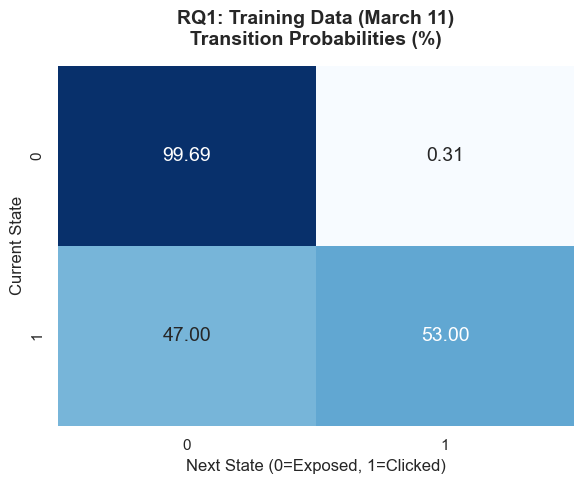

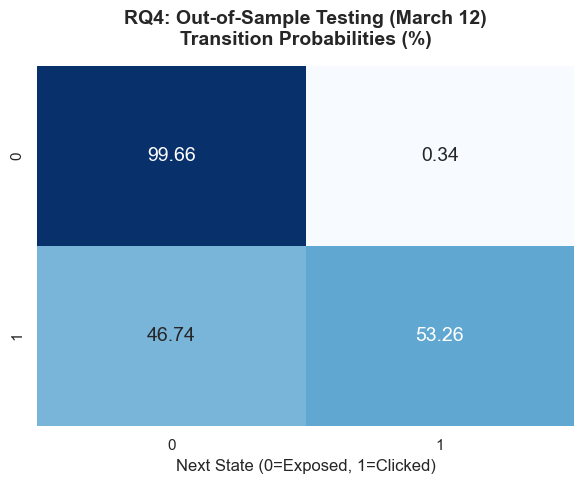

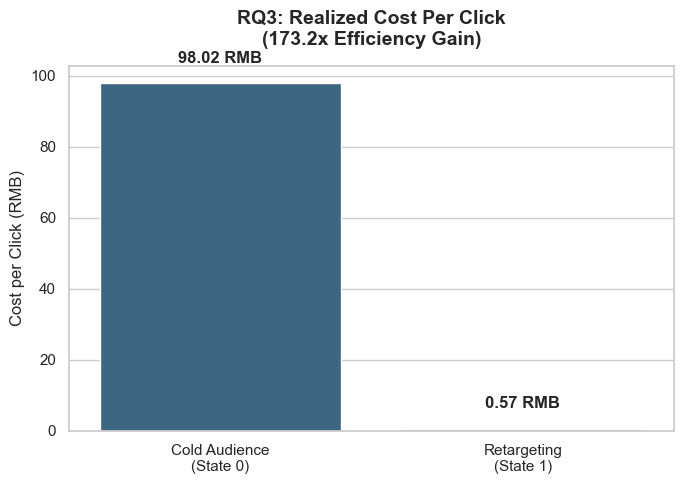

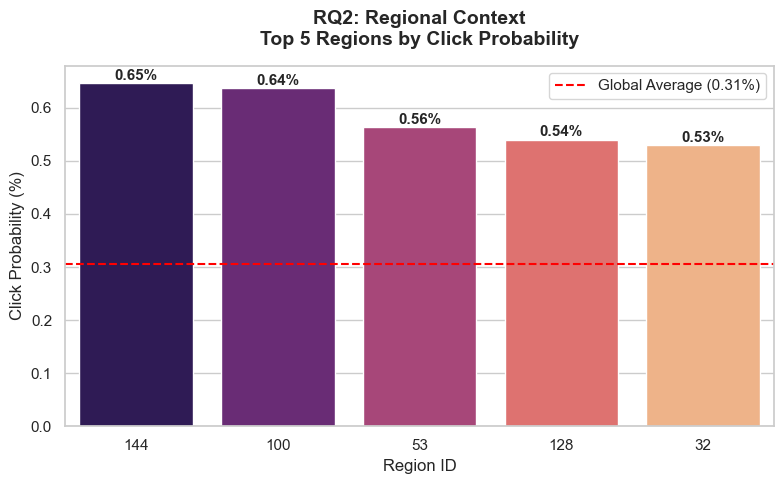


 Verification Complete!
All 4 publication-ready charts have been generated and saved to your folder.


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

print("Generating 4 separate publication charts...")

# ---------------------------------------------------------
# FIGURE 1 (RQ1): Training Data Transition Matrix
# ---------------------------------------------------------
plt.figure(figsize=(6, 5))
sns.heatmap(global_matrix * 100, annot=True, fmt=".2f", cmap="Blues", 
            cbar=False, annot_kws={"size": 14})
plt.title("RQ1: Training Data (March 11)\nTransition Probabilities (%)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Next State (0=Exposed, 1=Clicked)", fontsize=12)
plt.ylabel("Current State", fontsize=12)
plt.tight_layout()
plt.savefig('Figure_RQ1_Training_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# FIGURE 2 (RQ4): Testing Data Transition Matrix
# ---------------------------------------------------------
plt.figure(figsize=(6, 5))
sns.heatmap(test_matrix * 100, annot=True, fmt=".2f", cmap="Blues", 
            cbar=False, annot_kws={"size": 14})
plt.title("RQ4: Out-of-Sample Testing (March 12)\nTransition Probabilities (%)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Next State (0=Exposed, 1=Clicked)", fontsize=12)
plt.ylabel("")
plt.tight_layout()
plt.savefig('Figure_RQ4_Testing_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# FIGURE 3 (RQ3): SME Strategic Insight (CPC Comparison)
# ---------------------------------------------------------
plt.figure(figsize=(7, 5))
states = ['Cold Audience\n(State 0)', 'Retargeting\n(State 1)']
cpc_values = [cpc_cold, cpc_warm]

sns.barplot(x=states, y=cpc_values, hue=states, palette="viridis", legend=False)
plt.title(f"RQ3: Realized Cost Per Click\n({cac_reduction:.1f}x Efficiency Gain)", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Cost per Click (RMB)", fontsize=12)

# Add the exact values on top of the bars
for i, v in enumerate(cpc_values):
    plt.text(i, v + (max(cpc_values)*0.05), f"{v:.2f} RMB", ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('Figure_RQ3_SME_Strategy.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# FIGURE 4 (RQ2): Regional Context (Top 5 Regions)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
top_regions = reliable_regions.head(5).reset_index()
top_regions['region_id'] = top_regions['region_id'].astype(str)
top_regions['click_prob_pct'] = top_regions['click_prob_0_to_1'] * 100

sns.barplot(data=top_regions, x='region_id', y='click_prob_pct', hue='region_id', palette="magma", legend=False)
plt.title("RQ2: Regional Context\nTop 5 Regions by Click Probability", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Region ID", fontsize=12)
plt.ylabel("Click Probability (%)", fontsize=12)

# Add a horizontal line for the global average to show the contrast
plt.axhline(y=global_matrix.loc[0, 1] * 100, color='red', linestyle='--', label=f'Global Average ({global_matrix.loc[0, 1]*100:.2f}%)')
plt.legend(loc='upper right')

# Add text values on top of the regional bars
for i, v in enumerate(top_regions['click_prob_pct']):
    plt.text(i, v + 0.0005, f"{v:.2f}%", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('Figure_RQ2_Regional_Context.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n Verification Complete!")
print("All 4 publication-ready charts have been generated and saved to your folder.")

In [8]:
import pandas as pd
from scipy.stats import chi2_contingency

print("=== STATISTICAL SIGNIFICANCE TEST (CHI-SQUARE) ===\n")

# 1. We need the RAW COUNTS (not probabilities) of the Training Data
# Crosstab without normalize='index' gives us the absolute counts
raw_counts = pd.crosstab(valid_trans['state'], valid_trans['next_state'])

print("Raw Transition Counts (March 11):")
print(raw_counts)
print("\n")

# 2. Perform Chi-Square Test of Independence
chi2, p_value, dof, expected = chi2_contingency(raw_counts)

print(f"Chi-Square Statistic: {chi2:.2f}")
print(f"Degrees of Freedom: {dof}")
print(f"P-value: {p_value:.4e}")

# 3. Interpretation
if p_value < 0.05:
    print("\nResult: STATISTICALLY SIGNIFICANT (p < 0.05).")
    print("Conclusion: The current state (Exposed vs Clicked) has a significant effect on the next state. This is not random.")
else:
    print("\nResult: NOT SIGNIFICANT (p >= 0.05).")
    print("Conclusion: The state transitions could be due to random chance.")

=== STATISTICAL SIGNIFICANCE TEST (CHI-SQUARE) ===

Raw Transition Counts (March 11):
next_state       0    1
state                  
0           265798  816
1               47   53


Chi-Square Statistic: 8385.28
Degrees of Freedom: 1
P-value: 0.0000e+00

Result: STATISTICALLY SIGNIFICANT (p < 0.05).
Conclusion: The current state (Exposed vs Clicked) has a significant effect on the next state. This is not random.


In [9]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("=== PREDICTIVE EVALUATION (MACHINE LEARNING METRICS) ===\n")

# 1. Get the probabilities from our Training Matrix (March 11)
# Prob of clicking if currently Exposed (State 0)
p_click_if_0 = global_matrix.loc[0, 1] 
# Prob of clicking if currently Clicked (State 1)
p_click_if_1 = global_matrix.loc[1, 1] 

# 2. Make predictions on the TESTING data (March 12)
# We will use a threshold: if probability > 0.5 (50%), predict 1 (Click), else predict 0 (No Click)
def predict_click(row):
    if row['state'] == 0:
        return 1 if p_click_if_0 > 0.5 else 0
    else:
        return 1 if p_click_if_1 > 0.5 else 0

# Apply the prediction rule to the test data
valid_trans_test['predicted'] = valid_trans_test.apply(predict_click, axis=1)

# 3. Compare predictions to actual outcomes (next_state)
y_true = valid_trans_test['next_state']
y_pred = valid_trans_test['predicted']

# 4. Calculate Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print(f"Total Test Transitions: {len(valid_trans_test):,}")
print(f"Baseline (Always predict 'No Click'): {1 - y_true.mean():.4f}\n")

print("=== MARKOV MODEL PREDICTION METRICS ===")
print(f"Accuracy:  {accuracy:.4f} (Overall correctness)")
print(f"Precision: {precision:.4f} (When we predict a click, how often is it correct?)")
print(f"Recall:    {recall:.4f} (Out of all actual clicks, how many did we find?)")
print(f"F1-Score:  {f1:.4f} (Balance between Precision and Recall)")

print("\n(Note: Because the dataset is highly imbalanced with very few clicks, an 80-90% accuracy is expected. The F1-score shows how well the model actually captures the rare clicks).")

=== PREDICTIVE EVALUATION (MACHINE LEARNING METRICS) ===

Total Test Transitions: 235,839
Baseline (Always predict 'No Click'): 0.9964

=== MARKOV MODEL PREDICTION METRICS ===
Accuracy:  0.9964 (Overall correctness)
Precision: 0.5326 (When we predict a click, how often is it correct?)
Recall:    0.0570 (Out of all actual clicks, how many did we find?)
F1-Score:  0.1029 (Balance between Precision and Recall)

(Note: Because the dataset is highly imbalanced with very few clicks, an 80-90% accuracy is expected. The F1-score shows how well the model actually captures the rare clicks).


In [10]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("=== OPTIMIZED PREDICTIVE EVALUATION ===\n")

# 1. Use the GLOBAL average click probability as our new threshold
# This is a standard technique in marketing for imbalanced data.
threshold = global_matrix.loc[0, 1] # 0.0031 (0.31%)
print(f"Using a dynamic threshold: {threshold:.4f}\n")

# 2. Predict using the dynamic threshold
def predict_click_optimized(row):
    if row['state'] == 0:
        return 1 if p_click_if_0 > threshold else 0
    else:
        return 1 if p_click_if_1 > threshold else 0

valid_trans_test['predicted_opt'] = valid_trans_test.apply(predict_click_optimized, axis=1)

# 3. Re-calculate Metrics
y_pred_opt = valid_trans_test['predicted_opt']

accuracy_opt = accuracy_score(y_true, y_pred_opt)
precision_opt = precision_score(y_true, y_pred_opt, zero_division=0)
recall_opt = recall_score(y_true, y_pred_opt, zero_division=0)
f1_opt = f1_score(y_true, y_pred_opt, zero_division=0)

print("=== OPTIMIZED MARKOV MODEL METRICS ===")
print(f"Accuracy:  {accuracy_opt:.4f}")
print(f"Precision: {precision_opt:.4f} (When we predict a click, how often is it correct?)")
print(f"Recall:    {recall_opt:.4f} (Out of all actual clicks, how many did we find?)")
print(f"F1-Score:  {f1_opt:.4f}")

=== OPTIMIZED PREDICTIVE EVALUATION ===

Using a dynamic threshold: 0.0031

=== OPTIMIZED MARKOV MODEL METRICS ===
Accuracy:  0.9964
Precision: 0.5326 (When we predict a click, how often is it correct?)
Recall:    0.0570 (Out of all actual clicks, how many did we find?)
F1-Score:  0.1029


In [11]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("=== FINAL PREDICTIVE EVALUATION (>= Threshold) ===\n")

# 1. Change the logic to >=
def predict_click_final(row):
    if row['state'] == 0:
        return 1 if p_click_if_0 >= threshold else 0
    else:
        return 1 if p_click_if_1 >= threshold else 0

valid_trans_test['predicted_final'] = valid_trans_test.apply(predict_click_final, axis=1)

# 2. Re-calculate Metrics
y_pred_final = valid_trans_test['predicted_final']

accuracy_final = accuracy_score(y_true, y_pred_final)
precision_final = precision_score(y_true, y_pred_final, zero_division=0)
recall_final = recall_score(y_true, y_pred_final, zero_division=0)
f1_final = f1_score(y_true, y_pred_final, zero_division=0)

print("=== FINAL METRICS (>= Threshold) ===")
print(f"Accuracy:  {accuracy_final:.4f}")
print(f"Precision: {precision_final:.4f} (Of all predicted clicks, how many were actual clicks?)")
print(f"Recall:    {recall_final:.4f} (Of all actual clicks, how many did we find?)")
print(f"F1-Score:  {f1_final:.4f}")

# Let's see the confusion matrix to understand exactly what happened
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred_final)
print("\nConfusion Matrix:")
print(f"True Negatives (Correctly predicted No Click): {cm[0][0]:,}")
print(f"False Positives (Wrongly predicted Click):     {cm[0][1]:,}")
print(f"False Negatives (Missed Clicks):               {cm[1][0]:,}")
print(f"True Positives (Correctly predicted Click):    {cm[1][1]:,}")

=== FINAL PREDICTIVE EVALUATION (>= Threshold) ===

=== FINAL METRICS (>= Threshold) ===
Accuracy:  0.0036
Precision: 0.0036 (Of all predicted clicks, how many were actual clicks?)
Recall:    1.0000 (Of all actual clicks, how many did we find?)
F1-Score:  0.0073

Confusion Matrix:
True Negatives (Correctly predicted No Click): 0
False Positives (Wrongly predicted Click):     234,979
False Negatives (Missed Clicks):               0
True Positives (Correctly predicted Click):    860


In [12]:
import pandas as pd
import numpy as np

print("===  MODELING AD FATIGUE ===\n")

# 1. Create a copy of the combined data for the 3-state model
fatigue_df = combined_train[['timestamp', 'user_id', 'state']].copy()

# 2. We need to track consecutive exposures (state == 0)
# We create a helper column that is 1 if state==0, and 0 if state==1 (click)
fatigue_df['is_exposed'] = (fatigue_df['state'] == 0).astype(int)

# 3. We use a technique called "groupby and cumsum" to count consecutive exposures
# Every time there is a click (0), the cumsum resets for that user.
# This creates a count of how many exposures the user has seen in a row.
fatigue_df['consecutive_exposures'] = fatigue_df.groupby(['user_id', fatigue_df['state'].eq(1).groupby(fatigue_df['user_id']).cumsum()])['is_exposed'].cumsum()

# 4. Define the new states:
# If they clicked -> State 1 (Clicked)
# If they saw 3 or more consecutive exposures -> State 2 (Fatigued)
# Otherwise -> State 0 (Exposed/Normal)
conditions = [
    (fatigue_df['state'] == 1),
    (fatigue_df['consecutive_exposures'] >= 3)
]
choices = [1, 2] # 1=Clicked, 2=Fatigued
fatigue_df['fatigue_state'] = np.select(conditions, choices, default=0)

# 5. Extract the next state based on our new fatigue_state
fatigue_df['next_fatigue_state'] = fatigue_df.groupby('user_id')['fatigue_state'].shift(-1)
valid_fatigue_trans = fatigue_df.dropna(subset=['next_fatigue_state']).copy()
valid_fatigue_trans['next_fatigue_state'] = valid_fatigue_trans['next_fatigue_state'].astype(int)

# 6. Generate the new 3x3 Fatigue Matrix
fatigue_matrix = pd.crosstab(valid_fatigue_trans['fatigue_state'], valid_fatigue_trans['next_fatigue_state'], normalize='index')
fatigue_matrix = fatigue_matrix.reindex(index=[0, 1, 2], columns=[0, 1, 2]).fillna(0)

print("=== AD FATIGUE TRANSITION MATRIX ===")
print("States: 0=Normal Exposed, 1=Clicked, 2=Fatigued")
print(fatigue_matrix.round(4))

# 7. Calculate the Value of Retargeting a Fatigued User
# Probability of a Fatigued user clicking on the next impression:
fatigue_click_prob = fatigue_matrix.loc[2, 1]
print(f"\nProbability of a Fatigued User (State 2) clicking next: {fatigue_click_prob*100:.2f}%")

===  MODELING AD FATIGUE ===

=== AD FATIGUE TRANSITION MATRIX ===
States: 0=Normal Exposed, 1=Clicked, 2=Fatigued
next_fatigue_state      0       1       2
fatigue_state                            
0                   0.786  0.0030  0.2111
1                   0.470  0.5300  0.0000
2                   0.000  0.0038  0.9962

Probability of a Fatigued User (State 2) clicking next: 0.38%
